Going to be working through the Decision Trees chapter in the book using the iris dataset from sklearn

In [21]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_graphviz


In [22]:
iris = load_iris(as_frame=True)
X_iris = iris.data[['petal length (cm)', 'petal width (cm)']].values
y = iris.target

In [23]:
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_iris,y=y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [24]:
export_graphviz(
    tree_clf,
    out_file='trees.dot',
    feature_names=['petal length (cm)','petal width (cm)'],
    class_names=iris.target_names,
    rounded=True,
    filled=True
)

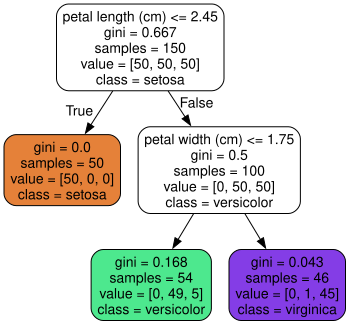

In [20]:
from graphviz import Source
Source.from_file('trees.dot')

Now lets get the probability that a given instance will be each of our classes (k values)
This works by taking in an instance with the features in an array and then it will traverse our trained tree and land in the leaf node (region) that those features would correspond with, then the probability is the proportion of each class in that region

In [28]:
example_probs = tree_clf.predict_proba([[4,2.1]]).round(3) #should give high proabbility for virginica because thats what had the highest proprition for training
example_probs

array([[0.   , 0.022, 0.978]])

Now lets use that same instance to get a prediction from our tree, it should predict k=2 because thats what the highest proprition is 

In [30]:
prediction1 = tree_clf.predict([[4,2.1]])
prediction1 #correct as we could see using the probabilities from the traversal

array([2])

Decision trees are a non-parametric model which means they do not have a starting limit as to how many parameters they can learn which means they can overfit the training data very easily if not regularized. Each split chooses the feature and threshold that will give the smallest gini cost score relative to number of leaves in that split and the features and thresholds are parameters, so this means it can have unlimited splits. We can use many different techniques to minimize the overfitting, I will use a few with hyperparameters

In [3]:
from sklearn.datasets import make_moons



In [32]:
X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)
tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(random_state=42,min_samples_leaf=5) #using regulairzation here to ensure a leaf node (new region) is only created when more than 5 instances
tree_clf1.fit(X_moons, y_moons)
tree_clf2.fit(X_moons, y_moons)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Testing each one's accuracy using a new test set. The second one should perform better because we generalized it more using the 
min_samples_leaf hyperparameter to ensure we did not create a region unless 5 or more instances would fall into it
The first one did not do this so it could have created as many splits as it wanted as long as they continued to decrease the impurity score of the node

In [ ]:
X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2, random_state=45)
no_reg = tree_clf1.score(X_moons_test, y_moons_test)
reg = tree_clf2.score(X_moons_test,y_moons_test)
#the regularized model score 2 percent better

Now moving into regression trees which are decision trees that predict a quantitative value rather than a qualitative value. 

In [56]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

In [57]:
X,y = load_diabetes(return_X_y=True,as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42
)
reg_tree = DecisionTreeRegressor(random_state=42)


In [60]:
reg_tree.fit(X_train,y_train)
score = reg_tree.score(X_test, y_test)
score


0.060653981041140725

The testing accuracy was only 6% which makes sense because I did not regularize the splits at all, so the tree could have split as far as it wanted to with as many parameters as it wanted. I'm not going to give it hyperparameters to make sure it generalzies better

In [78]:
reg_tree2 = DecisionTreeRegressor(random_state=43, min_samples_leaf=5, max_depth=3)

In [79]:
reg_tree2.fit(X_train, y_train)
score = reg_tree2.score(X_test, y_test)
score

0.4159289074356103

Now I am going to use the moons dataset to fine tune a decision tree

In [29]:
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [9]:
X,y  = make_moons(n_samples=1000, noise=0.4)

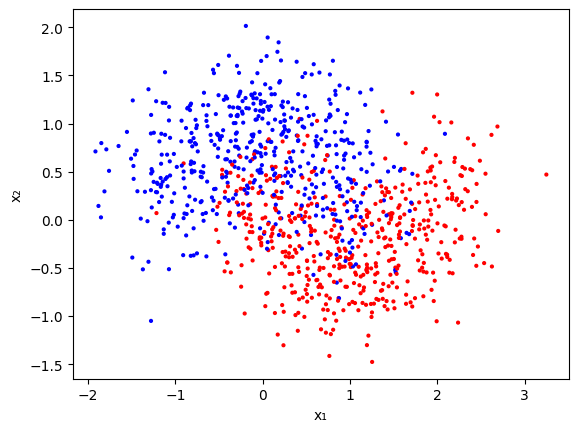

In [24]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=4,cmap='bwr')
plt.xlabel("x₁"); plt.ylabel("x₂")
plt.show()

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

Now going to use GridSearchCV to find good values for hyperparameters for the tree. It is going to take the hyperparams i give and then try then out using k fold CV and get the avg score of each for each CV cycle on the data the model had not seen in the last fold

In [34]:
tree_clf = DecisionTreeClassifier(random_state=42)
best_params = GridSearchCV(tree_clf, {
    'max_leaf_nodes': [2,3,4,5,9,12,15],
    'min_samples_split': [2,3,4,5,6,7,8,10,12]
}).fit(X,y=y)


Using cross validation for the search for the best hyperparameters we got that the max leaf nodes should be 4 and min samples per split should be 2 that gave the best avg cross validation scores for building and testing the cart

In [39]:
tree_clf = DecisionTreeClassifier(random_state=42, max_leaf_nodes=4, min_samples_split=2) #using the hyperparameters we found
tree_clf.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",4
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [42]:
train_score = tree_clf.score(X_train,y_train)
test_score = tree_clf.score(X_test, y_test)
test_score

0.905

In [51]:
tree_clf.tree_.threshold

array([ 0.33660907, -0.54531014,  1.59393257, -2.        , -2.        ,
       -2.        , -2.        ])

Since single trees have very high variance because it matters on the data it got for the splits, im going to make a random forest of 1000 trees to then avg them to get better predictions

In [71]:
from sklearn.model_selection import ShuffleSplit
from sklearn.metrics import accuracy_score

In [ ]:
sp = ShuffleSplit(n_splits=1000,train_size=100,random_state=42)
#take each train split to fit a new classification tree and store it in an array
trees = [] #keeps all the trees(fitted with best hyperparams we found using gridsearchcv)
for train_split, test_split in sp.split(X_train):
    tree = DecisionTreeClassifier(max_leaf_nodes=4).fit(X_train[train_split],y_train[train_split])
    trees.append(tree)

In [56]:
import numpy as np
#now get the avg accuracy of the trees so can see how good they are using only 100 rows
scores = [tree.score(X_test, y_test) for tree in trees]
mean_score = np.mean(scores)
mean_score

np.float64(0.8722449999999999)

In [65]:
#now we need to get a 2d array that has each prediction each tree makes for all the data points
#then we are going to take the most common prediction for each data point and use that
preds = np.zeros(shape=(1000,len(X_test)))
for i in range(1000):
    curr_preds = trees[i].predict(X_test) #gets prediction per point
    preds[i] = curr_preds


In [ ]:
#now we are going to take each prediction for each point and use the most common one
from scipy.stats import mode
y_vote = mode(preds,axis=0)


ModeResult(mode=array([1., 0., 0., 0., 1., 1., 0., 1., 0., 0., 1., 1., 1., 0., 0., 0., 1.,
       1., 1., 0., 1., 0., 1., 1., 1., 1., 1., 1., 0., 1., 0., 1., 1., 1.,
       1., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 1., 1., 1., 1., 0., 1.,
       0., 1., 0., 0., 0., 1., 0., 0., 1., 0., 1., 1., 0., 1., 0., 1., 1.,
       1., 0., 0., 0., 0., 1., 1., 1., 0., 0., 1., 0., 1., 1., 1., 1., 1.,
       1., 0., 0., 0., 1., 1., 0., 1., 0., 1., 1., 1., 0., 1., 0., 1., 0.,
       0., 1., 1., 1., 0., 1., 0., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0.,
       0., 0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 1., 1., 0., 0., 1., 0., 0., 1., 1., 0., 0., 0., 1.,
       1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 0., 1., 1., 1., 0., 0., 0.,
       0., 0., 1., 0., 0., 1., 0., 0., 1., 1., 1., 0., 1., 0., 1., 1., 1.,
       1., 1., 1., 0., 1., 1., 1., 1., 0., 1., 0., 1., 1.]), count=array([ 999,  784,  994,  995, 1000,  990,  996,  833,  990,  999, 1000,
        978, 1000, 

Now we can see how our predictions using the 1000 trees (random forest) most common prediction is compared to the test targets

In [76]:
forest_acc = accuracy_score(y_test, y_vote[0])
forest_acc

0.905